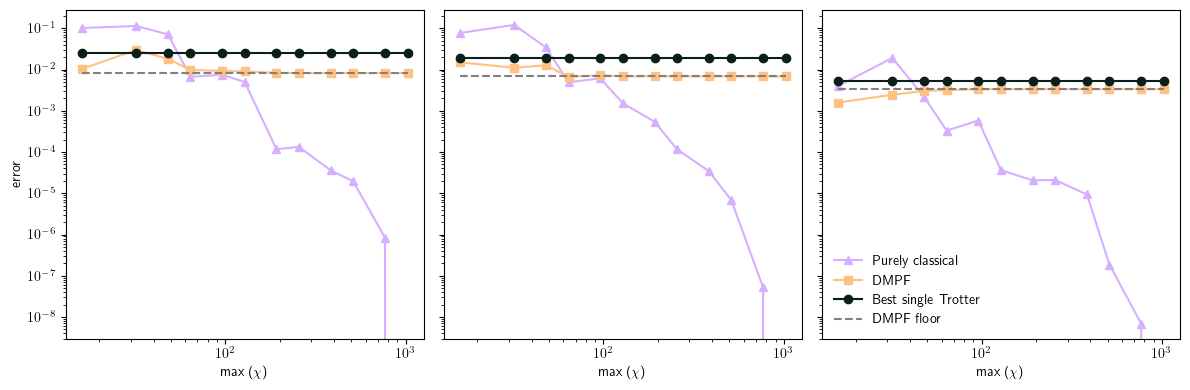

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 200

colors = ["#d6afff", "#ffc181", "#0a1f1c"]
markers = ["^", "s", "o"]
errors  = ["err_direct", "err_dmpf", "err_best_single"]
legend = ["Purely classical", "DMPF", "Best single Trotter"]

fam = "3-8"
obs = "ZZ_mid"
gammas = ["0.01", "0.05", "0.20"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4),
    sharey=True
)

for (sup_idx, g) in enumerate(gammas):
    df = pd.read_csv(f'../results/step2_capped/step2_scaling_cap{gammas[sup_idx]}.csv') 

    chi = df.loc[(df["family"] == fam) & (df["obs"] == obs), "chi"]
    floor = df.loc[(df["family"] == fam) & (df["obs"] == obs), "err_proj"]

    for (idx, label) in enumerate(errors):
        err = df.loc[(df["family"] == fam) & (df["obs"] == obs), label]
        axes[sup_idx].plot(chi, err, linestyle = "solid", color = colors[idx], marker = markers[idx], label = legend[idx])
        axes[sup_idx].set_yscale("log")
        axes[sup_idx].set_xscale("log")

    axes[sup_idx].plot(chi, floor, linestyle = "dashed", color = "grey", label = "DMPF floor")
    axes[sup_idx].set_xlabel("max ($\\chi$)")

axes[0].set_ylabel("error")
plt.legend(frameon = False)
plt.tight_layout()
plt.savefig(f"../results/error_scaling.png", bbox_inches='tight', transparent = True)
plt.show()

In [44]:
df["family"]

0      4-8-16
1      4-8-16
2      4-8-16
3      4-8-16
4      4-8-16
        ...  
307       3-8
308       3-8
309       3-8
310       3-8
311       3-8
Name: family, Length: 312, dtype: object

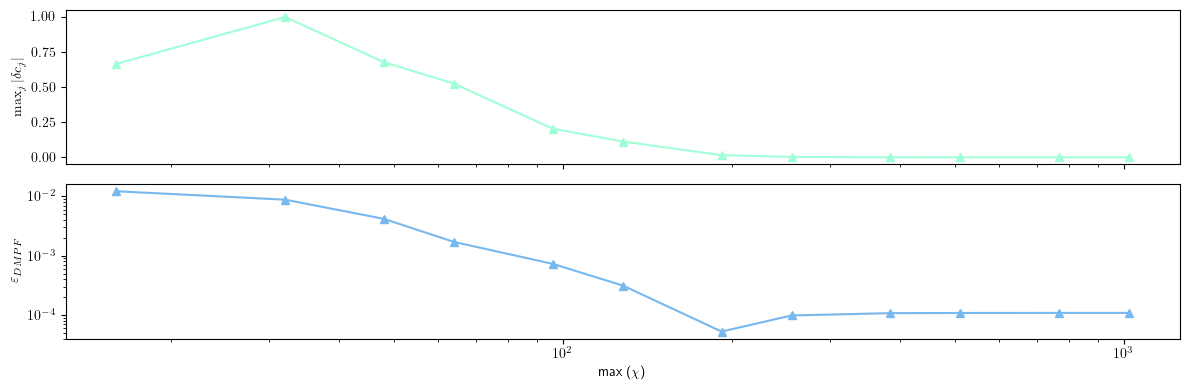

In [52]:
df = pd.read_csv(f'../results/step2_capped/step2_scaling_cap0.05.csv') 

fam = "4-8-16"
obs = "ZZ_mid"

colors = ["#a0ffd7", "#77b8ee"]

max_dc = df.loc[(df["family"] == fam) & (df["obs"] == obs), "dc_max"]
err_dmpf = df.loc[(df["family"] == fam) & (df["obs"] == obs), "err_dmpf"]
err_floor = df.loc[(df["family"] == fam) & (df["obs"] == obs), "err_proj"]
chi = df.loc[(df["family"] == fam) & (df["obs"] == obs), "chi"]

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 4),
    sharex=True
)

axes[0].plot(chi, max_dc, marker = "^", color = "#a0ffd7", linestyle = "solid")
# axes[0].plot(chi, np.ones(len(chi)), linestyle = "solid", color = "darkgrey")
axes[0].set_ylabel("$\\max_j |\\delta c_j|$")
axes[1].set_yscale("log")
axes[1].set_xscale("log")    

axes[1].plot(chi, err_dmpf, marker = "^", color = "#77b8ee", linestyle = "solid")
axes[1].set_ylabel("$\\varepsilon_{DMPF}$")
axes[1].set_xlabel("max ($\\chi$)")
axes[1].set_yscale("log")
axes[1].set_xscale("log")        

plt.tight_layout()
plt.savefig(f"../results/coefficient_error.png", bbox_inches='tight', transparent = True)
plt.show()